In [16]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Smart Irrigation Project")
print("Python:", sys.version.split()[0])
print("Environment:", sys.executable)
print("All libraries imported successfully!")

Smart Irrigation Project
Python: 3.13.5
Environment: d:\Documents\artificial_intelligence\Smart_Irrigation\.venv\Scripts\python.exe
All libraries imported successfully!


In [17]:
# ==========================================
# Smart Irrigation - Project Configuration
# ==========================================

PROJECT_NAME = "AI-Driven Smart Irrigation"

# Study location
LOCATION = "Bishkek, Kyrgyzstan"
LATITUDE = 42.8746
LONGITUDE = 74.5698

# Crop parameters
CROP = "Tomato"
SOIL_TYPE = "Loam"
ROOT_DEPTH = 0.5  # meters

# Simulation settings
TIME_STEP = 1  # day

print("PROJECT CONFIGURATION")
print("-" * 40)

print(f"Project: {PROJECT_NAME}")
print(f"Location: {LOCATION}")
print(f"Coordinates: {LATITUDE}, {LONGITUDE}")
print(f"Crop: {CROP}")
print(f"Soil Type: {SOIL_TYPE}")
print(f"Root Zone Depth: {ROOT_DEPTH} m")
print(f"Simulation Time Step: {TIME_STEP} day")

PROJECT CONFIGURATION
----------------------------------------
Project: AI-Driven Smart Irrigation
Location: Bishkek, Kyrgyzstan
Coordinates: 42.8746, 74.5698
Crop: Tomato
Soil Type: Loam
Root Zone Depth: 0.5 m
Simulation Time Step: 1 day


In [18]:
import requests
import pandas as pd
from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

# Open-Meteo Historical Weather API
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 42.8746,
    "longitude": 74.5698,
    "start_date": "2020-01-01",
    "end_date": "2025-12-31",
    "daily": [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "shortwave_radiation_sum"
    ],
    "hourly": ["relative_humidity_2m"],
    "wind_speed_unit": "ms",
    "timezone": "Asia/Bishkek"
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

data = response.json()

# Daily weather data
df = pd.DataFrame(data["daily"])

# Calculate daily average relative humidity
humidity = pd.DataFrame(data["hourly"])

humidity["date"] = pd.to_datetime(
    humidity["time"]
).dt.date.astype(str)

daily_humidity = (
    humidity.groupby("date")["relative_humidity_2m"]
    .mean()
    .reset_index()
)

# Combine weather data
df = df.merge(
    daily_humidity,
    left_on="time",
    right_on="date",
    how="left"
)

df = df.drop(columns=["date"])

# Save raw dataset
file_path = DATA_DIR / "weather_raw.csv"

df.to_csv(file_path, index=False)

print("Weather dataset downloaded successfully!")
print("Total records:", len(df))
print("Saved to:", file_path)

display(df.head())

Weather dataset downloaded successfully!
Total records: 2192
Saved to: d:\Documents\artificial_intelligence\Smart_Irrigation\data\weather_raw.csv


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,shortwave_radiation_sum,relative_humidity_2m
0,2020-01-01,0.6,-9.0,-3.3,0.2,1.76,8.21,94.208333
1,2020-01-02,0.1,-9.4,-5.2,0.0,1.88,8.46,75.916667
2,2020-01-03,2.0,-7.9,-2.4,1.2,1.54,5.64,68.625000
3,2020-01-04,1.8,-6.9,-2.5,0.0,1.84,8.14,75.666667
4,2020-01-05,1.1,-9.2,-3.5,0.0,1.91,8.86,57.666667


In [19]:
# ==========================================
# Dataset Inspection
# ==========================================

print("DATASET INFORMATION")
print("=" * 50)

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

DATASET INFORMATION

Dataset shape:
(2192, 8)

Column names:
['time', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'wind_speed_10m_mean', 'shortwave_radiation_sum', 'relative_humidity_2m']

Data types:
time                           str
temperature_2m_max         float64
temperature_2m_min         float64
temperature_2m_mean        float64
precipitation_sum          float64
wind_speed_10m_mean        float64
shortwave_radiation_sum    float64
relative_humidity_2m       float64
dtype: object

First 5 rows:


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,shortwave_radiation_sum,relative_humidity_2m
0,2020-01-01,0.6,-9.0,-3.3,0.2,1.76,8.21,94.208333
1,2020-01-02,0.1,-9.4,-5.2,0.0,1.88,8.46,75.916667
2,2020-01-03,2.0,-7.9,-2.4,1.2,1.54,5.64,68.625000
3,2020-01-04,1.8,-6.9,-2.5,0.0,1.84,8.14,75.666667
4,2020-01-05,1.1,-9.2,-3.5,0.0,1.91,8.86,57.666667



Last 5 rows:


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,shortwave_radiation_sum,relative_humidity_2m
2187,2025-12-27,-0.0,-5.3,-2.5,0.2,1.23,7.07,92.333333
2188,2025-12-28,4.8,-3.8,0.5,0.0,1.78,7.29,69.083333
2189,2025-12-29,6.8,-2.0,2.8,0.0,2.62,7.95,68.500000
2190,2025-12-30,11.9,-0.6,4.4,0.0,2.21,7.08,68.583333
2191,2025-12-31,11.9,1.0,4.6,7.0,2.61,5.66,80.250000


In [20]:
# ==========================================
# Missing Values
# ==========================================

print("MISSING VALUES ANALYSIS")
print("=" * 50)

missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

display(missing_report)

MISSING VALUES ANALYSIS


,Missing Values,Percentage (%)
time,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
temperature_2m_mean,0,0.0
precipitation_sum,0,0.0
wind_speed_10m_mean,0,0.0
shortwave_radiation_sum,0,0.0
relative_humidity_2m,0,0.0


In [21]:
# ==========================================
# Duplicate Records
# ==========================================

print("DUPLICATE ANALYSIS")
print("=" * 50)

duplicates = df.duplicated().sum()

duplicate_dates = df["time"].duplicated().sum()

print("Duplicate rows:", duplicates)
print("Duplicate dates:", duplicate_dates)

DUPLICATE ANALYSIS
Duplicate rows: 0
Duplicate dates: 0


In [22]:
# ==========================================
# Descriptive Statistics
# ==========================================

print("DESCRIPTIVE STATISTICS")
print("=" * 50)

display(df.describe().T)

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
temperature_2m_max,2192.0,17.315830,11.736408,-19.200000,7.700000,18.70,27.500000,40.000000
temperature_2m_min,2192.0,5.696168,10.197546,-29.400000,-2.200000,6.60,14.325000,26.300000
temperature_2m_mean,2192.0,11.386679,11.042737,-24.500000,2.300000,12.30,21.125000,31.400000
precipitation_sum,2192.0,2.059352,4.811212,0.000000,0.000000,0.00,1.225000,43.300000
wind_speed_10m_mean,2192.0,2.110269,0.669204,0.400000,1.670000,2.03,2.480000,4.720000
shortwave_radiation_sum,2192.0,15.731766,7.413040,1.000000,9.045000,15.67,22.245000,30.250000
relative_humidity_2m,2192.0,58.229319,18.467681,18.083333,43.333333,57.00,73.166667,98.958333


In [23]:
# ==========================================
# Physical Data Validation
# ==========================================

print("PHYSICAL DATA VALIDATION")
print("=" * 50)

checks = {
    "Negative precipitation":
        (df["precipitation_sum"] < 0).sum(),

    "Negative wind speed":
        (df["wind_speed_10m_mean"] < 0).sum(),

    "Negative solar radiation":
        (df["shortwave_radiation_sum"] < 0).sum(),

    "Invalid relative humidity":
        (
            (df["relative_humidity_2m"] < 0) |
            (df["relative_humidity_2m"] > 100)
        ).sum(),

    "Maximum temperature below minimum":
        (
            df["temperature_2m_max"] <
            df["temperature_2m_min"]
        ).sum()
}

for check, count in checks.items():
    print(f"{check}: {count}")

PHYSICAL DATA VALIDATION
Negative precipitation: 0
Negative wind speed: 0
Negative solar radiation: 0
Invalid relative humidity: 0
Maximum temperature below minimum: 0


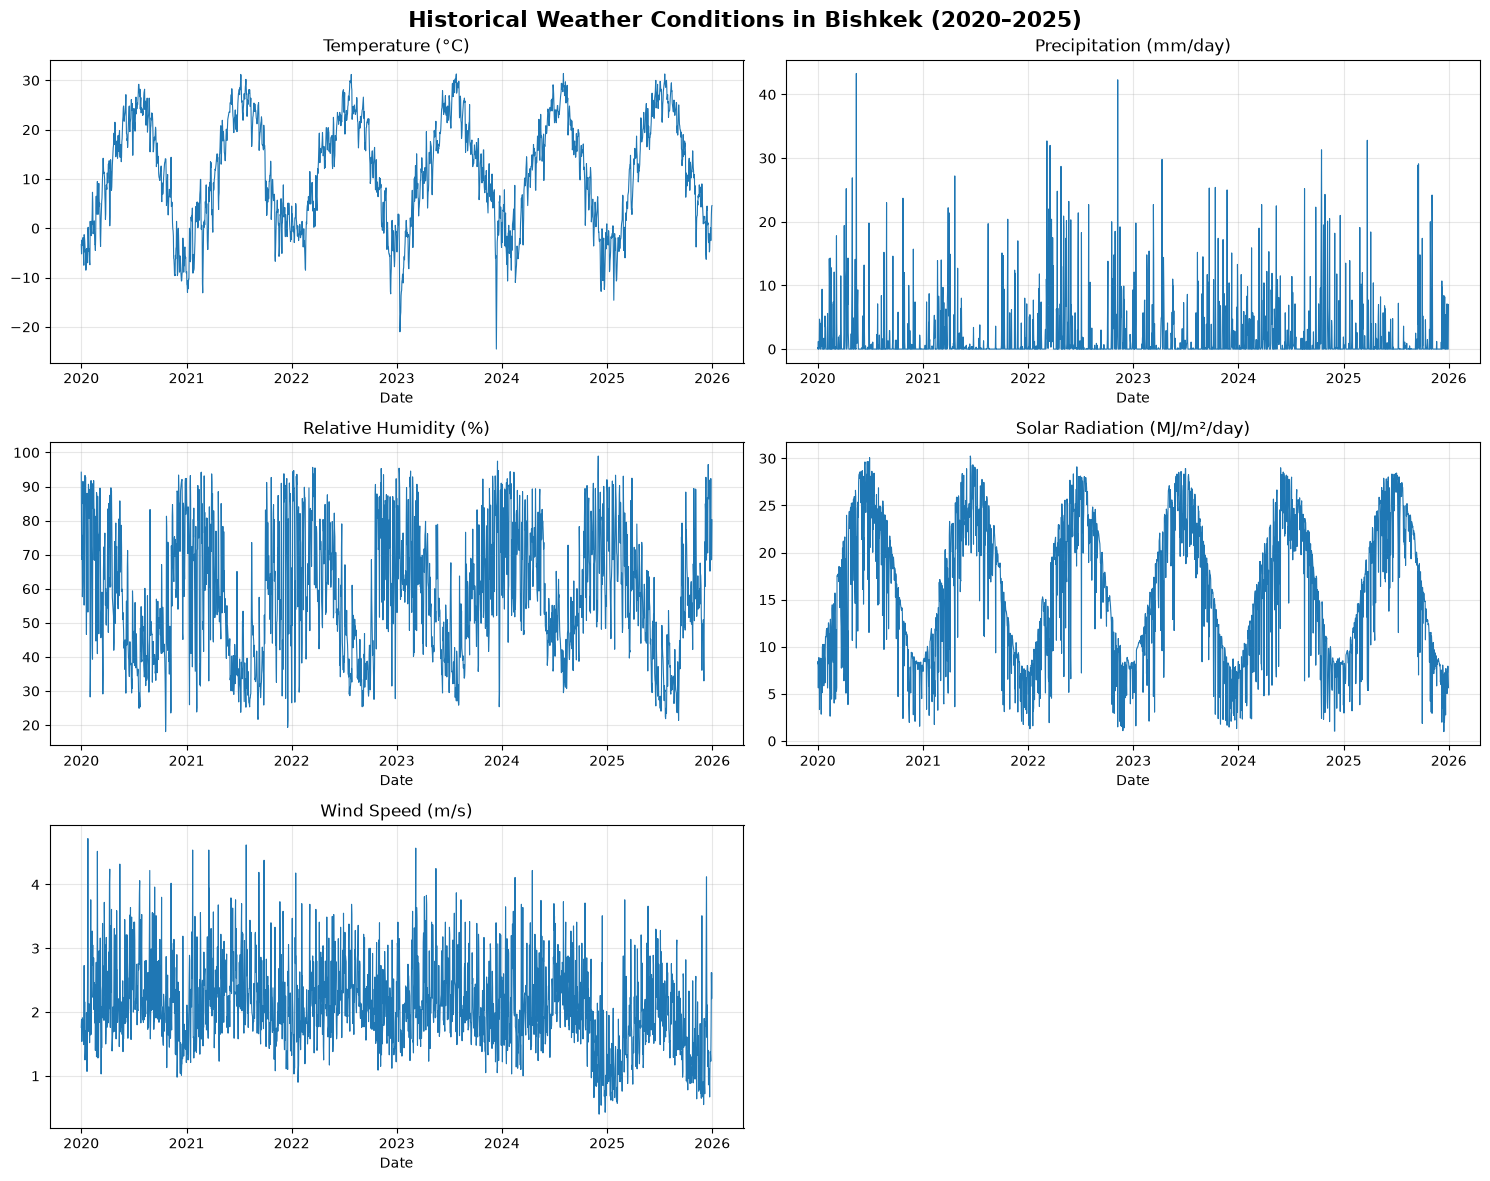

In [24]:
# ==========================================
# Weather Data Visualization
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

df["time"] = pd.to_datetime(df["time"])

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

variables = [
    ("temperature_2m_mean", "Temperature (°C)"),
    ("precipitation_sum", "Precipitation (mm/day)"),
    ("relative_humidity_2m", "Relative Humidity (%)"),
    ("shortwave_radiation_sum", "Solar Radiation (MJ/m²/day)"),
    ("wind_speed_10m_mean", "Wind Speed (m/s)")
]

for ax, (column, title) in zip(axes.flat, variables):
    ax.plot(df["time"], df[column], linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.grid(alpha=0.3)

axes.flat[-1].axis("off")

plt.suptitle(
    "Historical Weather Conditions in Bishkek (2020–2025)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

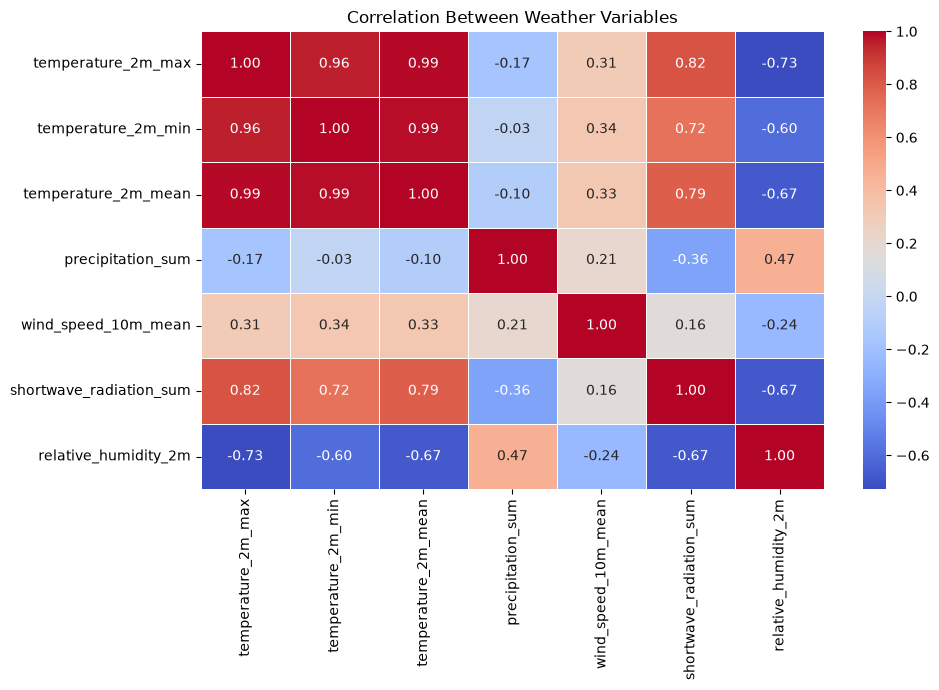

In [25]:
# ==========================================
# Correlation Analysis
# ==========================================

import seaborn as sns

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Weather Variables")
plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# Save Cleaned Dataset
# ==========================================

df = df.sort_values("time").reset_index(drop=True)

df["time"] = pd.to_datetime(df["time"])

cleaned_file = DATA_DIR / "weather_cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("File:", cleaned_file)
print("Total records:", len(df))
print("Total columns:", len(df.columns))

Cleaned dataset saved successfully!
File: d:\Documents\artificial_intelligence\Smart_Irrigation\data\weather_cleaned.csv
Total records: 2192
Total columns: 8


In [27]:
# ==========================================
# Reinforcement Learning Configuration
# ==========================================

STATE_FEATURES = [
    "soil_moisture",
    "temperature_2m_mean",
    "relative_humidity_2m",
    "shortwave_radiation_sum",
    "et0"
]

ACTIONS = {
    0: 0.0,  # No irrigation
    1: 2.0,  # Low irrigation
    2: 5.0,  # Medium irrigation
    3: 8.0   # High irrigation
}

EVALUATION_METRICS = [
    "total_water_consumption",
    "water_saving_percentage",
    "over_irrigation",
    "under_irrigation",
    "optimal_soil_moisture_percentage"
]

print("State features:", STATE_FEATURES)
print("Available actions:", ACTIONS)
print("Evaluation metrics:", EVALUATION_METRICS)

State features: ['soil_moisture', 'temperature_2m_mean', 'relative_humidity_2m', 'shortwave_radiation_sum', 'et0']
Available actions: {0: 0.0, 1: 2.0, 2: 5.0, 3: 8.0}
Evaluation metrics: ['total_water_consumption', 'water_saving_percentage', 'over_irrigation', 'under_irrigation', 'optimal_soil_moisture_percentage']


In [28]:

# ==========================================
# Growing Season Configuration
# ==========================================

import pandas as pd

GROWING_SEASON_START = 5   # May
GROWING_SEASON_END = 9     # September

df["time"] = pd.to_datetime(df["time"])

# Verify date continuity
expected_dates = pd.date_range(
    start=df["time"].min(),
    end=df["time"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(df["time"])

# Select the tomato growing season
growing_season_df = df[
    df["time"].dt.month.between(
        GROWING_SEASON_START,
        GROWING_SEASON_END
    )
].copy()

growing_season_df = growing_season_df.reset_index(drop=True)

# Save growing season dataset
season_file = DATA_DIR / "weather_growing_season.csv"
growing_season_df.to_csv(season_file, index=False)

print("GROWING SEASON CONFIGURATION")
print("=" * 50)
print("Crop:", CROP)
print("Location:", LOCATION)
print("Growing season: May - September")
print("Missing calendar dates:", len(missing_dates))
print("Growing season records:", len(growing_season_df))
print("Saved to:", season_file)

display(growing_season_df.head())


GROWING SEASON CONFIGURATION
Crop: Tomato
Location: Bishkek, Kyrgyzstan
Growing season: May - September
Missing calendar dates: 0
Growing season records: 918
Saved to: d:\Documents\artificial_intelligence\Smart_Irrigation\data\weather_growing_season.csv


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,shortwave_radiation_sum,relative_humidity_2m
0,2020-05-01,23.0,8.9,16.0,0.0,1.58,25.27,64.833333
1,2020-05-02,21.2,12.4,16.3,3.5,1.96,17.02,71.041667
2,2020-05-03,22.6,11.7,16.2,4.9,3.59,18.96,72.416667
3,2020-05-04,23.8,11.5,17.7,0.0,2.66,25.66,58.708333
4,2020-05-05,20.5,10.4,15.4,0.1,2.66,19.21,64.916667


In [29]:

# ==========================================
# Week 1 Final Validation
# ==========================================

required_columns = [
    "time",
    "temperature_2m_max",
    "temperature_2m_min",
    "temperature_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_mean",
    "shortwave_radiation_sum",
    "relative_humidity_2m"
]

missing_columns = [
    col for col in required_columns
    if col not in growing_season_df.columns
]

missing_values = growing_season_df[
    required_columns
].isna().sum().sum()

duplicate_dates = growing_season_df[
    "time"
].duplicated().sum()

print("WEEK 1 - FINAL VALIDATION")
print("=" * 50)

print("Required columns missing:", missing_columns)
print("Missing values:", missing_values)
print("Duplicate dates:", duplicate_dates)

assert not missing_columns, "Required columns are missing"
assert missing_values == 0, "Dataset contains missing values"
assert duplicate_dates == 0, "Dataset contains duplicate dates"
assert len(missing_dates) == 0, "Calendar dates are missing"

print("\nWeather data validation: PASSED")

print("\nNEXT STEPS")
print("- Calculate ET0 using FAO-56")
print("- Simulate soil moisture")
print("- Build Gymnasium environment")
print("- Implement DQN with PyTorch")


WEEK 1 - FINAL VALIDATION
Required columns missing: []
Missing values: 0
Duplicate dates: 0

Weather data validation: PASSED

NEXT STEPS
- Calculate ET0 using FAO-56
- Simulate soil moisture
- Build Gymnasium environment
- Implement DQN with PyTorch


# Week 1 — Research, Project Design and Data Preparation

## Project Overview

**Project Title:** AI-Driven Smart Irrigation Scheduling using In-Situ Moisture Sensor Arrays and Evapotranspiration Models

**Research Question:** Can integrating FAO-56 Penman–Monteith into a reinforcement learning reward function reduce over-irrigation and improve water-use efficiency?

**Research Objective:** Develop a simulation-based intelligent irrigation system using Deep Q-Networks (DQN) and physics-informed reinforcement learning to maintain suitable soil moisture while minimizing unnecessary water consumption.

## Study Configuration

| Parameter | Configuration |
|---|---|
| Location | Bishkek, Kyrgyzstan |
| Crop | Tomato |
| Soil type | Loam |
| Root-zone depth | 0.5 m |
| Simulation time step | 1 day |
| Weather period | January 2020 – December 2025 |
| Proposed growing season | May – September |
| Programming language | Python |

## Dataset

Historical weather data were obtained from the Open-Meteo Historical Weather API.

The dataset contains daily temperature, precipitation, wind speed, solar radiation, and daily average relative humidity derived from hourly observations.

The data were inspected for missing values, duplicate records, and physically invalid measurements. Descriptive statistics, weather visualizations, and correlation analysis were performed.

The original dataset was preserved, and a cleaned dataset was exported for subsequent processing.

## Reinforcement Learning Design

**State Space (proposed):**
- Soil moisture
- Mean air temperature
- Relative humidity
- Solar radiation
- Reference evapotranspiration (ET₀)

**Action Space (initial simulation values):**
- Action 0: No irrigation — 0 mm
- Action 1: Low irrigation — 2 mm
- Action 2: Medium irrigation — 5 mm
- Action 3: High irrigation — 8 mm

**Evaluation Metrics:**
- Total irrigation water consumption
- Water-saving percentage
- Over-irrigation
- Under-irrigation
- Percentage of time within the target soil-moisture range

## Assumptions and Limitations

The selected growing season is preliminary and will be treated as a simulation assumption.

The dataset contains weather observations but does not include measured soil moisture. Soil moisture will therefore be simulated using a soil-water balance model.

Reference evapotranspiration has not yet been calculated. FAO-56 implementation will require appropriate meteorological inputs, unit conversions, and assumptions for any unavailable variables.

The irrigation action amounts are initial design choices and may be adjusted after testing the physical simulation.

## Week 1 Outcome

The initial project configuration, weather data acquisition, data quality checks, descriptive analysis, visualizations, and reinforcement learning design have been prepared.

The next development phase will focus on FAO-56 Penman–Monteith calculations and soil-water balance simulation.